## Rama B — Capítulo 3

Este cuaderno desarrolla la teoría del Capítulo 3 (propagación en la celda) para la Rama B (semilla a 852 nm, señal a 794 nm) y genera la Figura 3.1, la transmisión de la semilla. Igual que en el cuaderno del Capítulo 2, cada sección indica qué cantidad física se calcula, de qué ecuación sale y qué conviene observar en la gráfica.

**Convenciones**

- Las tasas y desintonías se ingresan **divididas por $2\pi$, en MHz**, como en el Capítulo 2.
- A diferencia de las figuras del Capítulo 2, la transmisión $T_3=e^{-2\kappa_3L}$ no se puede normalizar: el exponente es un número absoluto. Por eso $\kappa_3$ se calcula **en SI** (m⁻¹), con $N$, $\lvert\mu_{ba}\rvert$, $L$, $\varepsilon_0$ y $\hbar$.
- Todas las constantes físicas se importan de `constants.py` (raíz del repositorio): las tasas de decaimiento, las frecuencias de transición, $\lvert\mu_{ba}\rvert$, la longitud de la celda y la presión de vapor del Cs, con la que se obtiene $N(T)$.
- Las figuras se guardan en `figuras/` en formato PDF.

In [3]:
import os
import sys
sys.path.append('../..')  # carpeta raíz del repositorio, donde está constants.py
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

from constants import c, hbar, eps0, g_ba, g_ca, w_ba, w_ca, w_cb, mu_ba, L_celda, n_Cs

plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

os.makedirs("figuras", exist_ok=True)

def guardar(fig, nombre):
    # Guarda la figura en figuras/<nombre>.pdf
    ruta = os.path.join("figuras", f"{nombre}.pdf")
    fig.savefig(ruta, bbox_inches="tight")
    print(f"Guardada: {ruta}")

## 1. Parámetros del modelo

La transmisión de la semilla, (3.26)–(3.27), depende de:

| Símbolo | Significado | De dónde sale |
|---|---|---|
| $\gamma_{ba}$ | decaimiento de la coherencia $\rho_{ba}$, ancho de la línea D2 | `g_ba` de `constants.py` |
| $\lvert\mu_{ba}\rvert$ | momento dipolar de $\lvert a\rangle\leftrightarrow\lvert b\rangle$ | `mu_ba` de `constants.py` |
| $N$ | densidad de átomos de Cs | `n_Cs(T)` de `constants.py`, presión de vapor a la temperatura de la celda |
| $L$ | longitud de la celda | `L_celda` de `constants.py` |
| $k_3$ | número de onda de vacío de la semilla, $\omega_3/c$ | frecuencia del láser de 852 nm (sección 2) |

**Momento dipolar.** El modelo de tres niveles trata la D2 como una transición de dos niveles. `constants.py` guarda el elemento reducido de Steck, $\langle J{=}1/2\Vert e\mathbf r\Vert J'{=}3/2\rangle$, y define

$$
\lvert\mu_{ba}\rvert^2 = \frac{2J+1}{2J'+1}\,\lvert\langle J\Vert e\mathbf r\Vert J'\rangle\rvert^2 = \tfrac12\,\lvert\langle J\Vert e\mathbf r\Vert J'\rangle\rvert^2 .
$$

Es el dipolo con el que la tasa de emisión espontánea de dos niveles,

$$
\Gamma = \frac{\omega_{ba}^3\,\lvert\mu_{ba}\rvert^2}{3\pi\varepsilon_0\hbar c^3},
$$

reproduce $\Gamma_{D2} = 2\gamma_{ba}$. La celda de abajo comprueba esa igualdad. Así el modelo es coherente: el mismo dipolo fija el ancho de la línea y la intensidad de la absorción.

**Densidad.** $N = P_v(T)/k_BT$, con la presión de vapor del Cs de Alcock, $\log_{10}(P_v/\mathrm{atm}) = A + B/T + C\log_{10}T$ (coeficientes de la fase líquida pues se manejan $T>30 ^\circ C$). La temperatura es la de la celda, no la `T[K]` de `constants.py`, que es la que fija la velocidad térmica $u$ en los cálculos con Doppler.

Las opciones de graficación (temperaturas de la celda, número de puntos, rango del eje) no son constantes físicas y pueden ajustarse libremente. Las temperaturas por defecto cubren el rango de las medidas de fluorescencia de la Rama B (50–80 °C); la detección a 794 nm se hizo a 60 °C.

In [ ]:
# --- Constantes físicas, desde constants.py ---------------------------------
# constants.py está en SI y rad/s; las desintonías van divididas por 2π, en MHz.
MHz = 2 * np.pi * 1e6   # rad/s que corresponden a 1 MHz de ω/2π

gamma_ba = g_ba / MHz             # γ_ba/2π : decaimiento de la coherencia ρ_ba (Γ_D2/2)
gamma_ca = g_ca / MHz             # γ_ca/2π : decaimiento de la coherencia de dos fotones ρ_ca
gamma_cb = gamma_ba + gamma_ca    # γ_cb/2π : decaimiento de la coherencia ρ_cb, (Γ_b + Γ_c)/2

# Frecuencias de transición /2π, en MHz (las usa `frecuencias_laser`)
nu_ba, nu_ca, nu_cb = w_ba / MHz, w_ca / MHz, w_cb / MHz

# --- Opciones de graficación -----------------------------------------------
N_PUNTOS   = 4001               # resolución de las curvas
RANGO_T12  = 2.5                # semiancho del eje, en múltiplos del mayor semiancho a T3 = 1/2
D2_FIJA    = 0.0                # desintonía de dos fotones del bombeo (MHz); T3 no depende de ella

# --- Comprobación del momento dipolar ---------------------------------------
Gamma_mu = w_ba**3 * mu_ba**2 / (3 * np.pi * eps0 * hbar * c**3) / MHz
print(f"|mu_ba| = {mu_ba:.4e} C m      L = {L_celda * 100:.2f} cm")
print(f"Gamma(mu_ba)/2pi = {Gamma_mu:.4f} MHz   2 gamma_ba/2pi = {2 * gamma_ba:.4f} MHz   "
      f"(diferencia relativa {abs(Gamma_mu / (2 * gamma_ba) - 1):.1e})")

|mu_ba| = 2.6850e-29 C m      L = 7.50 cm
Gamma(mu_ba)/2pi = 5.2226 MHz   2 gamma_ba/2pi = 5.2227 MHz   (diferencia relativa 1.6e-05)


## 2. Desintonías que se controlan en la Rama B

Igual que en el Capítulo 2, las dos perillas son la desintonía de dos fotones del bombeo, $\Delta_2 = \omega_{ca} - 2\omega_1$, y la de la semilla, $\Delta_3 = \omega_{ba} - \omega_3$. Invirtiendo estas definiciones se obtienen las frecuencias de los láseres, y la conservación de la energía (2.5) fija la de la señal:

$$
\omega_1 = \frac{\omega_{ca}-\Delta_2}{2}, \qquad
\omega_3 = \omega_{ba}-\Delta_3, \qquad
\omega_2 = 2\omega_1-\omega_3 .
$$

De ahí salen las desintonías restantes, (2.6) y (2.8):

$$
\Delta_1 = \omega_{ba}-\omega_1, \qquad \delta_2 = \omega_{cb}-\omega_2 = \Delta_2-\Delta_3 .
$$

Las funciones `frecuencias_laser` y `desintonias` son las mismas del Capítulo 2. En este capítulo aparece además el número de onda de cada campo. La ecuación de la semilla (3.19) usa $k_3=\omega_3/c$, y la función `numero_de_onda` lo calcula a partir de la frecuencia del láser que devuelve `frecuencias_laser`. Al barrer $\Delta_3$, $k_3$ cambia solo en una parte en $10^{5}$ respecto de su valor en resonancia, pero así se respeta la definición.

Para la Figura 3.1 solo importa $\Delta_3$; el bombeo se deja en `D2_FIJA` y no entra en $T_3$.

In [5]:
def frecuencias_laser(D2, D3):
    # Frecuencias /2π (MHz) de los tres campos a partir de las dos perillas (Δ2, Δ3)
    nu1 = (nu_ca - D2) / 2    # bombeo, 822 nm
    nu3 = nu_ba - D3          # semilla, 852 nm
    nu2 = 2 * nu1 - nu3       # señal, 794 nm: conservación de la energía (2.5)
    return nu1, nu2, nu3

def desintonias(D2, D3):
    # Devuelve (Δ1, δ2) según (2.6) y (2.8)
    nu1, nu2, nu3 = frecuencias_laser(D2, D3)
    D1 = nu_ba - nu1
    d2 = D2 - D3              # = nu_cb - nu2, sin el redondeo de restar números ~1e8 MHz
    return D1, d2

def numero_de_onda(nu):
    # Número de onda de vacío k = ω/c [rad/m], con nu = ω/2π en MHz
    return 2 * np.pi * nu * 1e6 / c

def lorentziana(x, gamma):
    # Perfil lorentziano normalizado a 1 en x = 0.
    return gamma**2 / (x**2 + gamma**2)

D1_0, _ = desintonias(D2_FIJA, 0.0)
k3_res = numero_de_onda(frecuencias_laser(D2_FIJA, 0.0)[2])
print(f"Delta1/2pi (Delta2 = {D2_FIJA:g}) = {D1_0 / 1e6:.4f} THz")
print(f"k3 (Delta3 = 0) = {k3_res:.6e} rad/m   ->   lambda3 = {2 * np.pi / k3_res * 1e9:.3f} nm")

Delta1/2pi (Delta2 = 0) = -12.7792 THz
k3 (Delta3 = 0) = 7.371626e+06 rad/m   ->   lambda3 = 852.347 nm


## 6. Propagación de la semilla (Sección 3.4.1)

$$
\tilde E_3(z) = \tilde E_3(0)\exp\!\Big(\frac{ik_3}{2}\chi^{(1)}(\omega_3)\,z\Big). \tag{3.22–3.23}
$$

Con $\chi^{(1)} = \chi^{(1)\prime}+i\chi^{(1)\prime\prime}$,

$$
\frac{ik_3}{2}\big(\chi^{(1)\prime}+i\chi^{(1)\prime\prime}\big) = -\kappa_3+i\beta_3,
\qquad \kappa_3 \equiv \frac{k_3\chi^{(1)\prime\prime}}{2},\quad \beta_3 \equiv \frac{k_3\chi^{(1)\prime}}{2},
\qquad
\tilde E_3(z) = \tilde E_3(0)\,e^{(-\kappa_3+i\beta_3)z}. \tag{3.24–3.25}
$$

$\kappa_3$ atenúa la amplitud; $\beta_3$ le agrega fase, de modo que el número de onda efectivo $k_3(1+\chi^{(1)\prime}/2)$ es $k_3$ por el índice del vapor. Con $\chi^{(1)}(\omega_3) = N\lvert\mu_{ba}\rvert^2/[\varepsilon_0\hbar(\Delta_3-i\gamma_{ba})]$:

$$
\kappa_3 = \frac{k_3N\lvert\mu_{ba}\rvert^2}{2\varepsilon_0\hbar}\,\frac{\gamma_{ba}}{\Delta_3^2+\gamma_{ba}^2},
\qquad
\beta_3 = \frac{k_3N\lvert\mu_{ba}\rvert^2}{2\varepsilon_0\hbar}\,\frac{\Delta_3}{\Delta_3^2+\gamma_{ba}^2},
\qquad
\beta_3 = \frac{\Delta_3}{\gamma_{ba}}\,\kappa_3. \tag{3.26}
$$

**Unidades.** En (3.26) las desintonías y $\gamma_{ba}$ van en rad/s. Como en el cuaderno se usan divididas por $2\pi$ en MHz, el cociente $\gamma_{ba}/(\Delta_3^2+\gamma_{ba}^2)$ se convierte a s/rad dividiendo por `MHz` $=2\pi\times10^6$.

La función `chi1` calcula $\chi^{(1)}(\omega_3)$ en SI (adimensional), y `kappa_beta_3` devuelve $(\kappa_3,\beta_3)$ en m⁻¹ a partir de las perillas, con $k_3$ tomado de la frecuencia del láser.

In [11]:
def chi1(D3, N):
    # χ(1)(ω3) del átomo en reposo, ec. (2.79), en SI. D3 en MHz (/2π), N en m^-3.
    return N * mu_ba**2 / (eps0 * hbar * (D3 - 1j * gamma_ba) * MHz)

def kappa_beta_3(D2, D3, N):
    # (κ3, β3) en m^-1, ecs. (3.24) y (3.26), con k3 = ω3/c de la frecuencia del láser de 852 nm
    k3 = numero_de_onda(frecuencias_laser(D2, D3)[2])
    exponente = 1j * k3 / 2 * chi1(D3, N)       # = -κ3 + iβ3
    return -exponente.real, exponente.imag

## 7. Figura 3.1 — Transmisión de la semilla

**Cantidad.** La transmisión en intensidad de la semilla a través de la celda, (3.27),

$$
T_3 = \frac{\lvert\tilde E_3(L)\rvert^2}{\lvert\tilde E_3(0)\rvert^2} = e^{-2\kappa_3L},
$$

con $\kappa_3$ de (3.26) para el átomo en reposo. $2\kappa_3L$ es la profundidad óptica de la semilla; su dependencia con $\Delta_3$ es la de la parte imaginaria de la Figura 2.5, una lorentziana de ancho $\gamma_{ba}$:

$$
2\kappa_3L = \mathrm{OD}_0\,L_{\gamma_{ba}}(\Delta_3), \qquad \mathrm{OD}_0 \equiv \frac{k_3N\lvert\mu_{ba}\rvert^2L}{\varepsilon_0\hbar\gamma_{ba}} .
$$

**Normalización.** No hay: $T_3$ es adimensional y el exponente es absoluto. Por eso esta es la primera figura que necesita $N$, $\lvert\mu_{ba}\rvert$ y $L$.

**Barrido.** Se barre la semilla, $\Delta_3$, para varias temperaturas de la celda (`T_CELDA_C`); cada una da una densidad $N(T)$. El bombeo queda en `D2_FIJA`.

In [14]:
T_C  = np.array([30,40, 50,70])
N_lista = n_Cs(T_C)

print(f"{'T (°C)':>7s} {'N (cm^-3)':>11s} {'kappa3(0) (1/m)':>16s} {'OD0 = 2 kappa3(0) L':>20s} "
      f"{'Delta3_1/2 /2pi (MHz)':>22s}")
D3_medio = []
for TC, N in zip(T_CELDA_C, N_lista):
    kap0, _ = kappa_beta_3(D2_FIJA, 0.0, N)
    OD0 = 2 * kap0 * L_celda
    D3_12 = gamma_ba * np.sqrt(OD0 / np.log(2) - 1)
    D3_medio.append(D3_12)
    print(f"{TC:7.0f} {N * 1e-6:11.3e} {kap0:16.4e} {OD0:20.4e} {D3_12:22.1f}")

 T (°C)   N (cm^-3)  kappa3(0) (1/m)  OD0 = 2 kappa3(0) L  Delta3_1/2 /2pi (MHz)
     50   7.969e+10       1.3822e+04           2.0732e+03                  142.8
     60   1.979e+11       3.4318e+04           5.1477e+03                  225.0
     70   4.633e+11       8.0360e+04           1.2054e+04                  344.4
     80   2.176e+12       3.7735e+05           5.6603e+04                  746.2


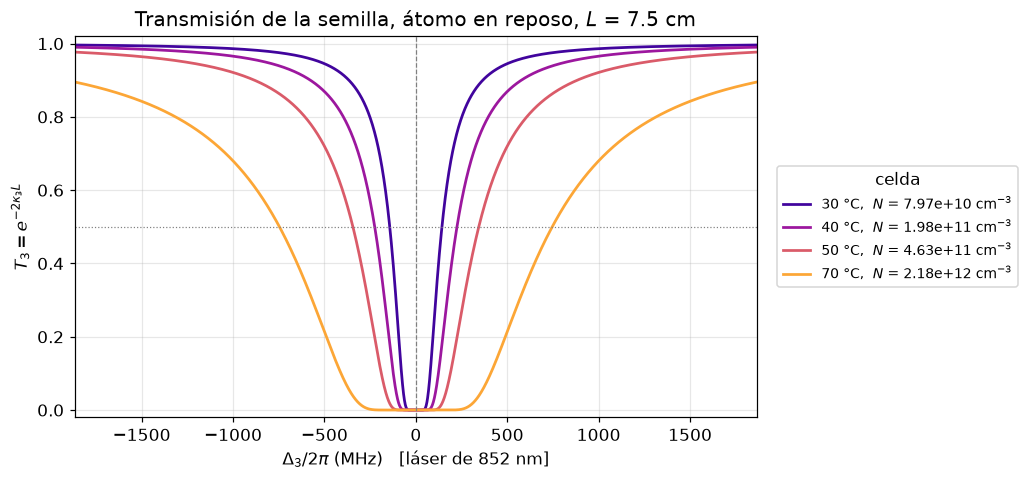

Guardada: figuras\F3-1_transmision_semilla.pdf


In [16]:
lim = RANGO_T12 * max(D3_medio)
D3 = np.linspace(-lim, lim, N_PUNTOS)

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = plt.cm.plasma(np.linspace(0.1, 0.8, len(T_C)))
for TC, N, color in zip(T_C, N_lista, colores):
    kap, _ = kappa_beta_3(D2_FIJA, D3, N)
    T3 = np.exp(-2 * kap * L_celda)
    ax.plot(D3, T3, color=color, lw=1.8,
            label=rf"{TC:.0f} °C,  $N$ = {N * 1e-6:.2e} cm$^{{-3}}$")
ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.axvline(0, color="gray", ls="--", lw=0.8)
ax.set_xlim(-lim, lim)
ax.set_ylim(-0.02, 1.02)
ax.set_xlabel(r"$\Delta_3/2\pi$ (MHz)   [láser de 852 nm]")
ax.set_ylabel(r"$T_3 = e^{-2\kappa_3 L}$")
ax.set_title(rf"Transmisión de la semilla, átomo en reposo, $L$ = {L_celda * 100:.1f} cm")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9, title="celda")
plt.show()
guardar(fig, "F3-1_transmision_semilla")

**Qué observar.**

- **La celda es opaca en un rango ancho alrededor de la D2.** Con $\mathrm{OD}_0\sim10^4$–$10^5$, la semilla solo atraviesa la celda a cientos de MHz de la resonancia. Lejos de ella, $2\kappa_3L\approx\mathrm{OD}_0\,\gamma_{ba}^2/\Delta_3^2$, así que la ventana se abre en $\Delta_{3,1/2}\propto\sqrt{N}$: multiplicar la densidad por ≈ 9 (de 50 a 80 °C) solo triplica el ancho del pozo.
- **El pozo es simétrico en $\Delta_3$**, porque solo entra $\chi^{(1)\prime\prime}$. La parte real, $\beta_3$, cambia la fase de la semilla y no su intensidad; en la señal reaparece a través de $\tilde E_3^*(z)$ en la fuente (punto 2 de la Sección 3.4.2).
- **Límites del modelo.** El átomo en reposo sobreestima mucho la profundidad óptica en resonancia: el promedio Doppler (pendiente) reparte la misma área en un ancho $\sim k_3u$, cientos de MHz, y baja el máximo en un factor $\sim\gamma_{ba}/k_3u$. Tampoco se incluye la estructura hiperfina de 6P3/2, que se extiende por ≈ 600 MHz, ni la saturación $1-2\rho_{bb}^{(2)}$. La figura muestra la escala de la absorción lineal del átomo en reposo, no el pozo que se mide.

## 8. Consecuencias para la señal (Sección 3.4.2)

La solución (3.25) entra en la ecuación de la señal (3.18). La primera consecuencia es que **la absorción de la señal depende de $z$**. La intensidad de la semilla es

$$
\lvert\tilde E_3(z)\rvert^2 = \tilde E_3(z)\,\tilde E_3^*(z) = \lvert\tilde E_3(0)\rvert^2\,e^{-\kappa_3z}e^{i\beta_3z}\,e^{-\kappa_3z}e^{-i\beta_3z} = \lvert\tilde E_3(0)\rvert^2\,e^{-2\kappa_3z}: \tag{3.28}
$$

la fase $\beta_3$ se cancela y solo queda la atenuación. Como $\rho_{bb}^{(2)}\propto\lvert\tilde E_3\rvert^2$, (2.52),

$$
\rho_{bb}^{(2)}(z) = \rho_{bb}^{(2)}(0)\,e^{-2\kappa_3z}. \tag{3.29}
$$

Por (2.87), $\chi_{\text{pop}}(z) = \chi^{(3)}_{\text{pop}}\lvert\tilde E_3(z)\rvert^2$, y el término cruzado es $\chi^{(3)}_{X,B}\lvert\tilde E_3(z)\rvert^2$. Con

$$
\chi^{(3)}_{\text{ef}} \equiv \chi^{(3)}_{X,B}+\chi^{(3)}_{\text{pop}}, \tag{3.30}
$$

la susceptibilidad efectiva (3.7) es

$$
\chi_{\text{ef}}(z) = \chi_{\text{ef}}(0)\,e^{-2\kappa_3z}, \qquad \chi_{\text{ef}}(0) = \chi^{(3)}_{\text{ef}}\lvert\tilde E_3(0)\rvert^2. \tag{3.31}
$$

La forma de $\chi_{\text{ef}}$ en función de las desintonías (Figura F4 del Capítulo 2) es la misma en toda la celda; lo que decae es su escala. La señal se absorbe más a la entrada, donde la semilla es intensa, y el vapor se vuelve transparente a 794 nm a medida que la semilla se consume. La escala de ese decaimiento es la misma $1/2\kappa_3$ de la Figura 3.1. La celda siguiente la evalúa: con la semilla en resonancia, la semilla, y con ella $\chi_{\text{ef}}$, desaparecen en los primeros micrómetros de la celda; para que $\chi_{\text{ef}}$ actúe a lo largo de toda la celda, la semilla tiene que estar en el borde de la ventana de transmisión, a cientos de MHz de la D2.

In [8]:
# Longitud en la que la intensidad de la semilla, y con ella χ_ef(z), cae en 1/e: 1/(2κ3), ec. (3.31)
casos_D3 = [0.0, 100.0, 300.0, 1000.0]   # MHz
print(f"{'T (°C)':>7s}" + "".join(f"{f'Delta3 = {d:g} MHz':>18s}" for d in casos_D3))
for TC, N in zip(T_CELDA_C, N_lista):
    fila = f"{TC:7.0f}"
    for d in casos_D3:
        kap, _ = kappa_beta_3(D2_FIJA, d, N)
        fila += f"{1 / (2 * kap) * 1e3:15.3g} mm"
    print(fila)
print(f"(longitud de la celda: {L_celda * 1e3:.0f} mm)")

 T (°C)    Delta3 = 0 MHz  Delta3 = 100 MHz  Delta3 = 300 MHz Delta3 = 1000 MHz
     50        0.00617 mm           9.06 mm           81.5 mm            905 mm
     60        0.00281 mm           4.12 mm             37 mm            411 mm
     70        0.00134 mm           1.96 mm           17.6 mm            196 mm
     80       0.000664 mm          0.975 mm           8.77 mm           97.4 mm
(longitud de la celda: 75 mm)
